<a href="https://colab.research.google.com/github/victorealeal/mod-1---regress-o/blob/main/previsao-aluguel-regressao-linear.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MÓDULO 18 - Pratique**
# Regressão Linear

Agora que aprendemos como aplicar a regressão linear simples e múltipla, colocaremos em prática os conceitos vistos na aula.

Temos aqui uma base de imóveis para alugar, precisamos desenvolver um modelo de regressão linear múltipla para conseguir prever o preço de imóveis dadas as variáveis independentes do nosso modelo.

**Atenção! Esse é seu primeiro modelo, caso tenha dificuldade conte com a ajuda da tutoria**

Você notará que alguns códigos já estão presentes para facilitar a construção de vocês.

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import numpy as np

In [2]:
import pandas as pd

# Lendo o arquivo diretamente da pasta local onde você o anexou
caminho_arquivo = '/content/ALUGUEL_MOD12.csv'

df = pd.read_csv(caminho_arquivo, delimiter=';')
df.head(10)

,Valor_Aluguel,Valor_Condominio,Metragem,N_Quartos,N_banheiros,N_Suites,N_Vagas
0,480,295,48,2,2,1,1
1,500,0,50,1,2,1,1
2,500,0,40,1,2,1,1
3,500,36,45,1,2,1,0
4,500,0,30,1,1,0,0
5,500,380,66,2,1,0,1
6,550,100,48,2,2,1,1
7,600,110,46,2,2,1,1
8,600,100,49,2,2,1,1
9,600,325,50,2,2,1,1


Legenda dos dados:

*   **Valor_Aluguel** : valor Total pago no aluguel

*   **Valor_Condominio** : Valor do Condomínio.

*   **Metragem** : Metragem do Apartamento.

*   **N_Quartos** : Número de Quartos do Imóvel.

*   **N_banheiros** : Número de banheiros.

*   **N_Suites** : Número de Suítes.

*   **N_Vagas** : Número de Vagas.

# 1 - Realize a primeira etapa de pré processamento dos dados.

A) Verifique os tipos de dados.


B) Verifique os dados faltantes, se houver dados faltantes faça a substituição ou remoção justificando sua escolha.

In [3]:
print(df.dtypes)

# Nulos explícitos (NaN)
print(df.isnull().sum())

# Percentual de nulos por coluna
print((df.isnull().mean() * 100).round(2))

# Nulos disfarçados: zeros em colunas onde 0 não faz sentido
print((df[['Valor_Aluguel', 'Metragem', 'N_Quartos', 'N_banheiros']] == 0).sum())


Valor_Aluguel       int64
Valor_Condominio    int64
Metragem            int64
N_Quartos           int64
N_banheiros         int64
N_Suites            int64
N_Vagas             int64
dtype: object
Valor_Aluguel       0
Valor_Condominio    0
Metragem            0
N_Quartos           0
N_banheiros         0
N_Suites            0
N_Vagas             0
dtype: int64
Valor_Aluguel       0.0
Valor_Condominio    0.0
Metragem            0.0
N_Quartos           0.0
N_banheiros         0.0
N_Suites            0.0
N_Vagas             0.0
dtype: float64
Valor_Aluguel    0
Metragem         0
N_Quartos        0
N_banheiros      0
dtype: int64


Não há dados faltantes, portanto, não há necessidade de substituir ou remover nada.

# 2 - Realize a segunda etapa de pré processamento dos dados.

A) Utilize a função describe para identificarmos outliers e verificarmos a distribuição dos dados.


B) Caso note uma variável que te pareça conter outliers realiza a análise e tratamento desses dados, justificando a escolha do método utilizado.

C) Realize a análise bivariada dos dados. Faça uso de pelo menos 3 gráficos e traga insights acerca do analisado.

       Valor_Aluguel  Valor_Condominio     Metragem    N_Quartos  N_banheiros  \
count    7203.000000       7203.000000  7203.000000  7203.000000  7203.000000   
mean     2966.596140        811.538109    88.506178     2.300153     2.095932   
std      2948.720385        796.564846    61.567505     0.826615     0.983812   
min       480.000000          0.000000    30.000000     1.000000     1.000000   
25%      1350.000000        395.000000    52.000000     2.000000     2.000000   
50%      2000.000000        592.000000    67.000000     2.000000     2.000000   
75%      3200.000000        980.000000   100.000000     3.000000     2.000000   
max     25000.000000       9500.000000   880.000000    10.000000     8.000000   

          N_Suites     N_Vagas  
count  7203.000000  7203.00000  
mean      1.016660     1.44176  
std       0.874204     0.86993  
min       0.000000     0.00000  
25%       1.000000     1.00000  
50%       1.000000     1.00000  
75%       1.000000     2.00000  
max   

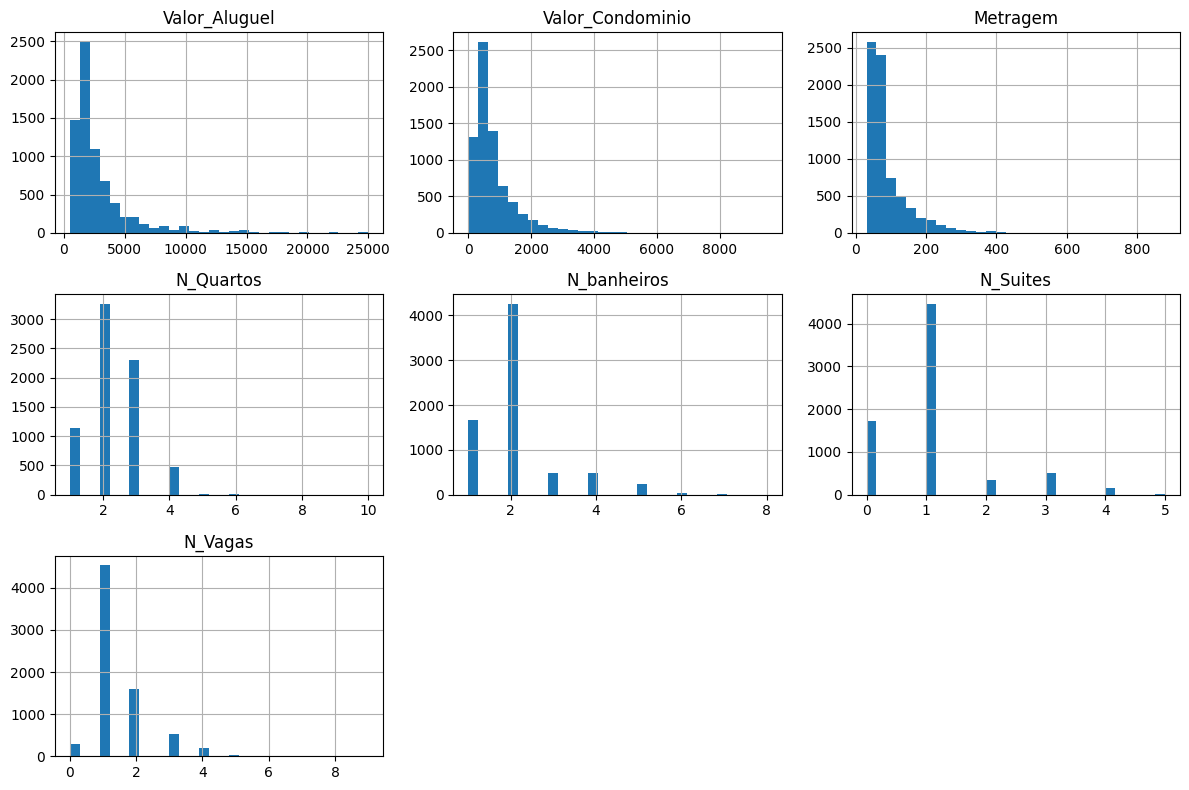

In [4]:
print(df.describe())

df.hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()


O describe mostrou que Valor_Aluguel, Valor_Condominio e Metragem têm a média acima da mediana e o valor máximo muito distante do 3º quartil, indicando distribuição assimétrica à direita e possível presença de outliers.

As variáveis N_Quartos, N_banheiros, N_Suites e N_Vagas apresentam assimetria à direita, mas são contagens discretas cujos valores mais altos são plausíveis e possuem frequência relevante, formando uma sequência gradual e não valores isolados. Além disso, o método do IQR não é adequado a elas, pois com poucos valores distintos o IQR é nulo ou muito pequeno e classificaria como outlier valores comuns. Portanto, foram mantidas.

Valor_Aluguel: limite superior = 5975 | outliers = 749 (10.4%)
Valor_Condominio: limite superior = 1858 | outliers = 586 (8.1%)
Metragem: limite superior = 172 | outliers = 647 (9.0%)


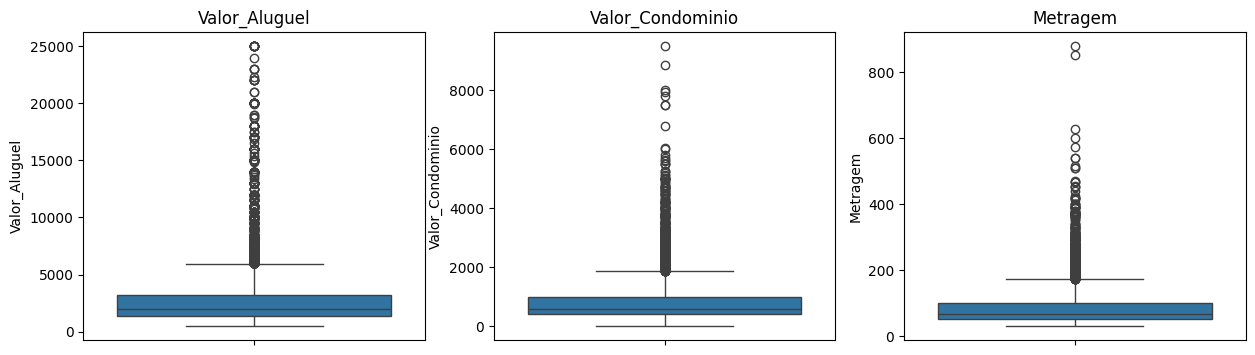

Remoção total seria de 1053 linhas (14.6%)
      Valor_Aluguel  Valor_Condominio  Metragem  N_Quartos  N_banheiros  \
7166          19900              7800       880          5            4   
6841           8700              5040       852          7            6   
7198          25000              7500       627          4            5   
7201          25000              6000       600          4            5   
6862           9000              2280       574          4            1   
7171          20000              4690       540          4            3   
7172          20000              5030       540          4            3   
6382           5500              2750       516          4            5   
6853           9000              4583       510          5            5   
6786           8000              4200       510          6            5   
7176          20000              4800       470          4            5   
7174          20000              5705       469          

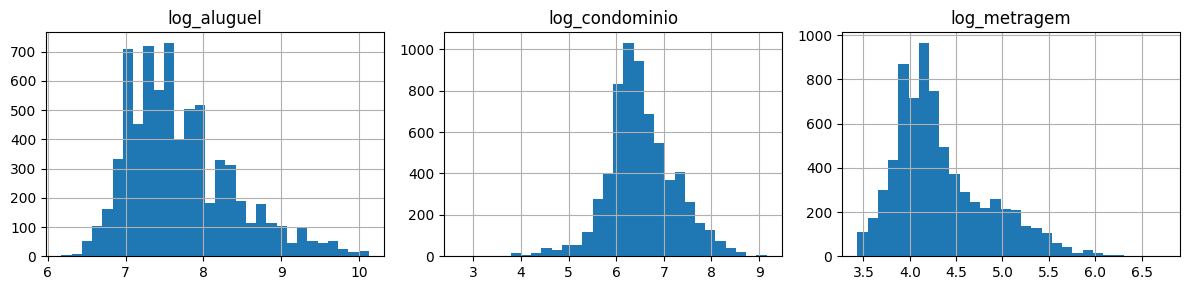

In [5]:
# ==========================================================
# ITEM B - Análise e tratamento de outliers
# ==========================================================


# %% 1. Função que calcula os limites do IQR
def limites_iqr(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

# %% 2. Quantos outliers existem em cada variável contínua?
colunas_continuas = ['Valor_Aluguel', 'Valor_Condominio', 'Metragem']

for col in colunas_continuas:
    li, ls = limites_iqr(df[col])
    n = (df[col] > ls).sum()
    print(f"{col}: limite superior = {ls:.0f} | outliers = {n} ({n/len(df)*100:.1f}%)")

# %% 3. Boxplots para visualizar os outliers
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, colunas_continuas):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.show()

# %% 4. Quanto custaria remover todos os outliers de uma vez?
li_a, ls_a = limites_iqr(df['Valor_Aluguel'])
li_c, ls_c = limites_iqr(df['Valor_Condominio'])
li_m, ls_m = limites_iqr(df['Metragem'])

mantidos = df[(df['Valor_Aluguel'] <= ls_a) &
              (df['Valor_Condominio'] <= ls_c) &
              (df['Metragem'] <= ls_m)]
removidos = len(df) - len(mantidos)
print(f"Remoção total seria de {removidos} linhas ({removidos/len(df)*100:.1f}%)")
# Decisão: 14,6% é muito e os imóveis são de alto padrão reais -> MANTER e usar log.

# %% 5. Inspecionar os maiores imóveis (são coerentes ou parecem erro?)
print(df[df['Metragem'] > 400].sort_values('Metragem', ascending=False))

# %% 6. Começar o tratamento a partir de uma cópia
df_tratado = df.copy()

# 6.1 Remover incoerências lógicas: mais suítes do que banheiros
n_incoerentes = (df_tratado['N_Suites'] > df_tratado['N_banheiros']).sum()
print(f"{n_incoerentes} imóveis com mais suítes do que banheiros")   # esperado: 31
df_tratado = df_tratado[df_tratado['N_Suites'] <= df_tratado['N_banheiros']].copy()

# 6.2 Remover condomínios irreais (placeholders de R$ 1 a R$ 10)
irreais = (df_tratado['Valor_Condominio'] > 0) & (df_tratado['Valor_Condominio'] <= 10)
print(f"{irreais.sum()} imóveis com condomínio irreal")              # esperado: 18
df_tratado = df_tratado[~irreais].copy()

print("Linhas restantes:", len(df_tratado))                          # esperado: 7154

# %% 7. Transformação logarítmica (reduz a assimetria sem perder linhas)
df_tratado['log_aluguel'] = np.log1p(df_tratado['Valor_Aluguel'])
df_tratado['log_metragem'] = np.log1p(df_tratado['Metragem'])

# Condomínio: zero é legítimo (imóvel sem condomínio).
# Criamos um indicador e aplicamos o log só a quem tem condomínio.
df_tratado['sem_condominio'] = (df_tratado['Valor_Condominio'] == 0).astype(int)
df_tratado['log_condominio'] = np.log(df_tratado['Valor_Condominio'].replace(0, np.nan))

# %% 8. Conferir o resultado: assimetria (skew) antes e depois
antes = df_tratado[['Valor_Aluguel', 'Valor_Condominio', 'Metragem']].skew().round(2)
depois = df_tratado[['log_aluguel', 'log_condominio', 'log_metragem']].skew().round(2)
print("Skew ANTES (valores originais):\n", antes, "\n")
print("Skew DEPOIS (com log):\n", depois)

# %% 9. Histogramas das variáveis transformadas
df_tratado[['log_aluguel', 'log_condominio', 'log_metragem']].hist(
    bins=30, figsize=(12, 3), layout=(1, 3))
plt.tight_layout()
plt.show()

1. Identificação dos outliers

A função describe mostrou que Valor_Aluguel, Valor_Condominio e Metragem têm a média acima da mediana (por exemplo, aluguel: média de R$ 2.967 contra mediana de R$ 2.000) e valores máximos muito distantes do terceiro quartil (metragem máxima de 880 m² contra Q3 de 100 m²). Isso indica distribuições assimétricas à direita e possíveis outliers. Para confirmar, utilizou-se o método do IQR (valores acima de Q3 + 1,5 × IQR), escolhido por se basear em quartis, que não são distorcidos por valores extremos, e por não exigir que os dados tenham distribuição normal. O método identificou 749 outliers em aluguel (10,4%), 586 em condomínio (8,1%) e 647 em metragem (9,0%). Os limites inferiores foram negativos, então não há outliers inferiores.

2. Variáveis de contagem

N_Quartos, N_banheiros, N_Suites e N_Vagas também apresentam cauda à direita, mas foram mantidas sem tratamento: seus valores mais altos são plausíveis (casas grandes) e frequentes o bastante para formar um grupo real do mercado. Além disso, o IQR não é adequado a variáveis com poucos valores distintos, pois em algumas delas Q1 e Q3 coincidem e o método marcaria como outlier valores perfeitamente comuns.

3. Decisão sobre aluguel, condomínio e metragem

A remoção simultânea de todos os outliers eliminaria 1.053 imóveis (14,6% da base). Além disso, a inspeção dos maiores imóveis mostrou que seus valores são coerentes entre si (metragem, aluguel, condomínio, quartos e vagas elevados), caracterizando imóveis de alto padrão reais, e não erros de registro. Removê-los enviesaria a análise para imóveis de padrão médio. Por isso, optou-se por manter as observações e aplicar a transformação logarítmica, que reduz o efeito dos valores extremos sem perder dados. A assimetria caiu de 3,27 para 0,89 no aluguel e de 2,79 para 0,94 na metragem.

4. Caso especial: condomínio

Cerca de 640 imóveis têm condomínio igual a zero, o que é legítimo (casas, por exemplo). Esses zeros, ao receberem o log, formaram um pico isolado que gerou assimetria negativa (-2,25). Por isso, criou-se a variável indicadora sem_condominio e o log foi aplicado apenas aos valores positivos. Ainda restou assimetria (-1,29), causada por condomínios de valor irreal: houve um pico isolado em R$ 1 (15 casos) e 3 casos de R$ 10, sem nenhuma ocorrência de R$ 2 a R$ 5, padrão típico de preenchimento placeholder. Esses 18 registros (0,25% da base) foram removidos, e a assimetria final do condomínio ficou em 0,04.

5. Incoerências lógicas

Foram removidos 31 imóveis (0,4% da base) com mais suítes do que banheiros, pois uma suíte é um quarto com banheiro próprio, o que torna o registro contraditório e provável erro de digitação. A quantidade pequena indica erros isolados, e não um padrão da fonte de dados.

6. Resultado

Ao todo foram removidos 49 registros (0,7%), e a base tratada ficou com 7.154 imóveis. A maior parte da informação foi preservada, e as distribuições ficaram mais simétricas para as análises seguintes.

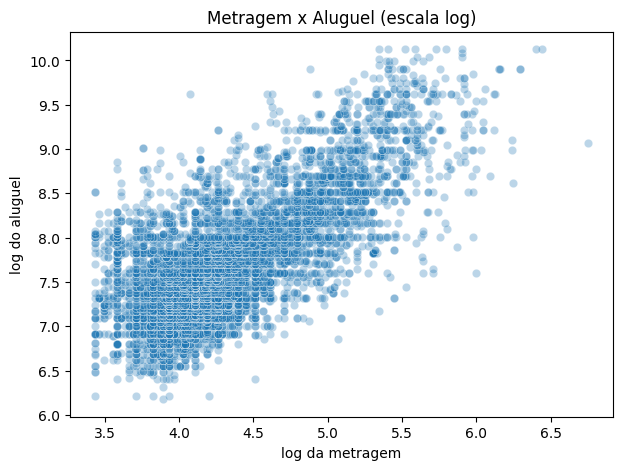

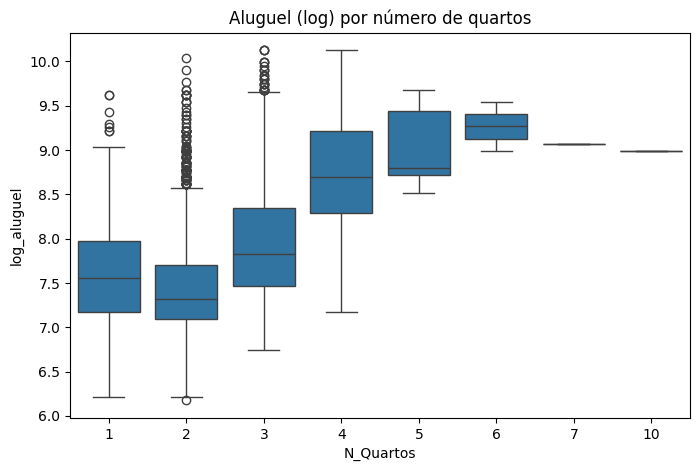

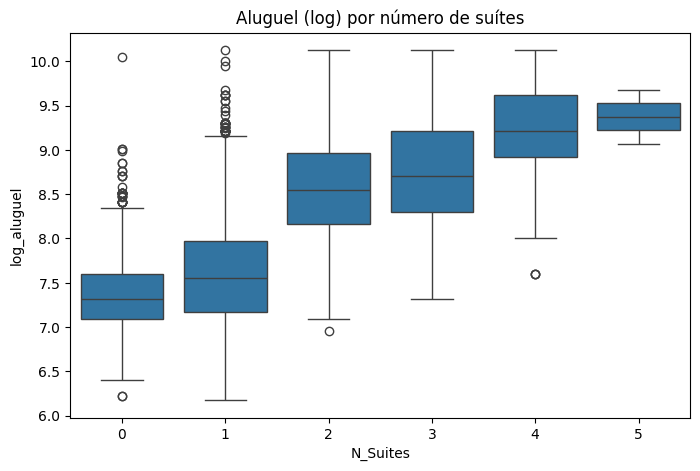

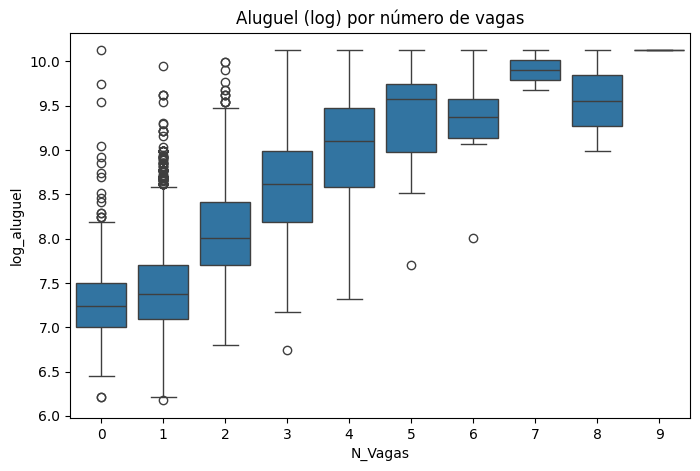

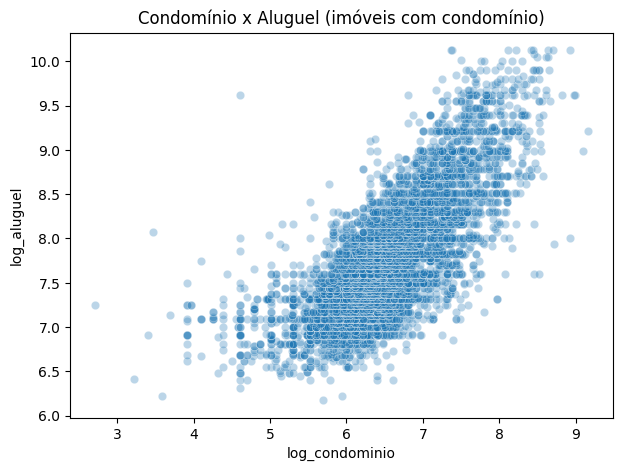

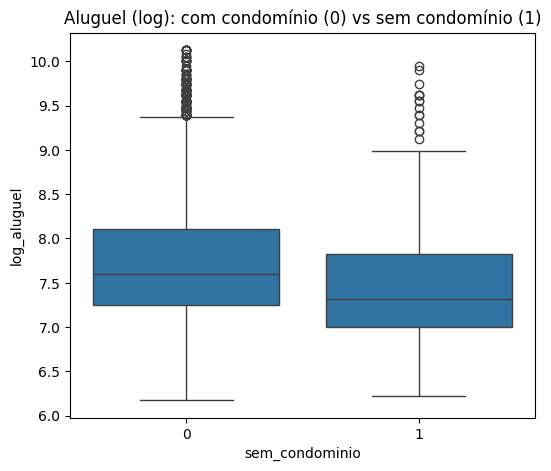


Aluguel mediano por N_Quartos:
           count   median
N_Quartos                
1           1138   1900.0
2           3255   1500.0
3           2289   2500.0
4            458   6000.0
5             10   6600.0
6              2  11000.0
7              1   8700.0
10             1   8000.0

Aluguel mediano por N_Suites:
          count   median
N_Suites                
0          1710   1500.0
1          4460   1900.0
2           340   5150.0
3           500   6000.0
4           142  10000.0
5             2  12350.0

Aluguel mediano por N_Vagas:
         count   median
N_Vagas                
0          292   1400.0
1         4518   1600.0
2         1588   3000.0
3          508   5500.0
4          198   9000.0
5           38  14500.0
6            7  11700.0
7            2  20500.0
8            2  16500.0
9            1  25000.0

Aluguel mediano (0 = com condomínio, 1 = sem):
sem_condominio
0    2000.0
1    1500.0
Name: Valor_Aluguel, dtype: float64

Aluguel por m² (resumo):
count    7

In [6]:
# ==========================================================
# ITEM C - Análise bivariada

# %% 1. GRÁFICO 1 - Metragem x Aluguel (dois números -> dispersão)
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_tratado, x='log_metragem', y='log_aluguel', alpha=0.3)
plt.title('Metragem x Aluguel (escala log)')
plt.xlabel('log da metragem')
plt.ylabel('log do aluguel')
plt.show()

# %% 2. GRÁFICO 2 - Nº de quartos x Aluguel (grupos -> boxplot)
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_tratado, x='N_Quartos', y='log_aluguel')
plt.title('Aluguel (log) por número de quartos')
plt.show()

# %% 3. GRÁFICO 3 - Nº de suítes x Aluguel
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_tratado, x='N_Suites', y='log_aluguel')
plt.title('Aluguel (log) por número de suítes')
plt.show()

# %% 4. GRÁFICO 4 - Nº de vagas x Aluguel
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_tratado, x='N_Vagas', y='log_aluguel')
plt.title('Aluguel (log) por número de vagas')
plt.show()

# %% 5. GRÁFICO 5 - Condomínio x Aluguel (só imóveis com condomínio)
com_cond = df_tratado[df_tratado['sem_condominio'] == 0]
plt.figure(figsize=(7, 5))
sns.scatterplot(data=com_cond, x='log_condominio', y='log_aluguel', alpha=0.3)
plt.title('Condomínio x Aluguel (imóveis com condomínio)')
plt.show()

# %% 6. GRÁFICO 6 - Com condomínio (0) x sem condomínio (1)
plt.figure(figsize=(6, 5))
sns.boxplot(data=df_tratado, x='sem_condominio', y='log_aluguel')
plt.title('Aluguel (log): com condomínio (0) vs sem condomínio (1)')
plt.show()

# %% 7. Tabelas com números reais (ajudam a escrever os insights)
# Aluguel mediano por número de quartos, suítes e vagas
for col in ['N_Quartos', 'N_Suites', 'N_Vagas']:
    print(f"\nAluguel mediano por {col}:")
    print(df_tratado.groupby(col)['Valor_Aluguel']
          .agg(['count', 'median']).round(0))

# Aluguel mediano: com x sem condomínio
print("\nAluguel mediano (0 = com condomínio, 1 = sem):")
print(df_tratado.groupby('sem_condominio')['Valor_Aluguel'].median())

# Aluguel por m², para comparar imóveis de tamanhos diferentes
df_tratado['aluguel_por_m2'] = df_tratado['Valor_Aluguel'] / df_tratado['Metragem']
print("\nAluguel por m² (resumo):")
print(df_tratado['aluguel_por_m2'].describe().round(1))

Graficos 1 de dispersão sobre metragem vs aluguel:
-  observa-se uma assoiação positiva;
- Os pontos tendem a subir da esquerda para a direita. Isso indica que, em geral, quanto maior a metragem do imóvel, maior tende a ser o valor do aluguel.
- Além disso, para imóveis com metragem semelhante, há diferentes valores de aluguel. Isso sugere que outros fatores também podem influenciar o preço, como localização, número de quartos, estado de conservação e infraestrutura;
Grafico 5 de dispersão sobre condominio vs aliuguel:
- observa-se uma associação positiva;
- Iimóveis com condomínio mais caro tendem a apresentar aluguéis mais elevados.
- Como o gráfico considera apenas imóveis com condomínio, a conclusão se aplica a esse grupo. Além disso, condomínio e aluguel podem estar associados porque ambos refletem características do imóvel, como localização, padrão e infraestrutura — isso não significa que o condomínio mais caro cause diretamente um aluguel maior.
- O possível padrão não linear indicam que essa relação deve ser investigada em conjunto com outras características dos imóveis.

Graficos de boxplots:

1. Aluguel por número de quartos
- Observa-se uma tendência de aumento do aluguel conforme aumenta o número de quartos.
- Imóveis com 4 ou mais quartos apresentam, em geral, medianas de aluguel superiores às categorias com menos quartos.
- Isso sugere uma associação positiva entre o número de quartos e o valor do aluguel.

2. Aluguel por número de suítes
- O gráfico indica que imóveis com mais suítes tendem a apresentar aluguéis mais elevados. A diferença é particularmente visível entre imóveis com até uma suíte e aqueles com duas ou mais, sugerindo que essa característica está associada a imóveis de maior valor de locação.

3. Aluguel por número de vagas de garagem
- Existe uma tendência geral de aumento do aluguel conforme aumenta o número de vagas de garagem. Imóveis com mais vagas apresentam, em geral, medianas de aluguel superiores, embora esse crescimento não seja uniforme em todas as categorias.

4. Aluguel com e sem condomínio
- Os imóveis sem condomínio apresentam uma mediana de aluguel ligeiramente superior à dos imóveis com condomínio.
- Entretanto, existe sobreposição considerável entre as distribuições, indicando que a presença de condomínio, isoladamente, não distingue claramente os valores de aluguel.


Essas interpretações descrevem associações observadas nos dados, sem estabelecer relações de causalidade.

# 3 - Realize a terceira etapa de pré processamento dos dados.

A) Comece pela correlação, que sabemos ser uma parte importante para nosso pré processamento e análise. Plote o gráfico ou a tabela e indique as variáveis que te parecem mais "fortes" na correlação para nosso modelo.




,Correlação com aluguel
Valor_Aluguel,0.893825
log_condominio,0.744431
log_metragem,0.725921
Metragem,0.711099
Valor_Condominio,0.683075
N_Vagas,0.655811
N_banheiros,0.616956
aluguel_por_m2,0.611289
N_Suites,0.603669
N_Quartos,0.436446


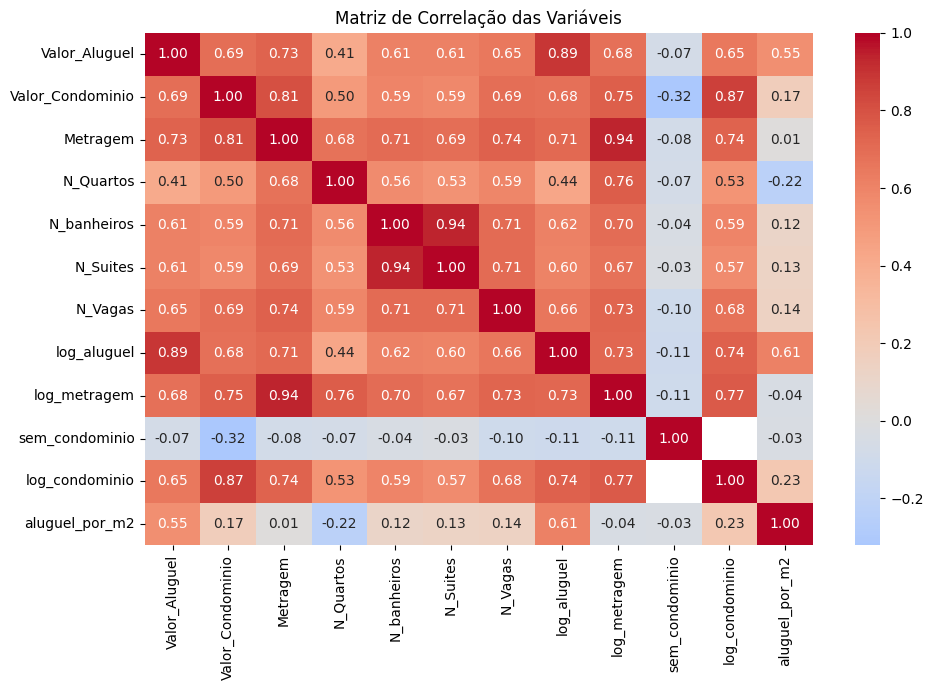

In [7]:
# Selecionar variáveis numéricas
df_corr = df_tratado.select_dtypes(include='number')

# Calcular correlações
corr = df_corr.corr()

# Mostrar correlação com o aluguel, da mais forte para a mais fraca
display(
    corr['log_aluguel']
    .drop('log_aluguel')
    .sort_values(key=abs, ascending=False)
    .to_frame('Correlação com aluguel')
)

# Visualizar matriz
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.title('Matriz de Correlação das Variáveis')
plt.tight_layout()
plt.show()

A análise da matriz de correlação identificou associações positivas entre o valor do aluguel e variáveis como log_metragem (r = 0,73), log_condominio (r = 0,74), N_Vagas (r = 0,66), N_banheiros (r = 0,62) e N_Suites (r = 0,60). Esses resultados sugerem que imóveis maiores, com mais vagas, banheiros e suítes, além de valores de condomínio mais elevados, tendem a apresentar aluguéis maiores.

Também foi observada uma correlação elevada entre N_banheiros e N_Suites (r = 0,94), indicando possível multicolinearidade. Portanto, além da associação de cada variável com o aluguel, é importante avaliar a relação entre as variáveis explicativas para evitar redundâncias no modelo. A correlação representa associação linear e, isoladamente, não comprova causalidade.


B) Durante a aula, por nossa base ser pequena e demonstrativa não realizamos a separação de treino e teste, porém para as atividades do dia dia temos que fazer, nesse exercício separe treino e teste.

Lembre-se que primeiro separamos as variaveis dependentes X e depois Y, essa etapa deixarei para vocês abaixo:

In [8]:
X = df.drop('Valor_Aluguel', axis=1) #Separando X - Todas variáveis exceto valor_aluguel
y = df['Valor_Aluguel'] #Separando Y (Apenas variavel valor_aluguel)

Dica: Para separar em treino e teste usamos o train_test_split, como visto nas aulas de pré modelagem.

In [9]:
from sklearn.model_selection import train_test_split

# Separar as variáveis independentes (X) e dependente (y)
X = df_tratado[['log_metragem', 'log_condominio', 'sem_condominio',
                'N_Quartos', 'N_banheiros', 'N_Suites', 'N_Vagas']]

y = df_tratado['log_aluguel']

# Separar os dados em treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Conferir as dimensões
print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

X_train: (5723, 7)
X_test: (1431, 7)
y_train: (5723,)
y_test: (1431,)


# 4 - Treine um modelo de regressão Linear simples

A) Vamos utilizar apenas X_train e y_train para rodar um modelo de regressão linea simples e para isso usaremos apenas uma váriavel, a váriavel metragem.

In [10]:
# Variável independente (X): metragem
X_train_simples = X_train[['log_metragem']]

# Variável dependente (y): aluguel
y_train_simples = y_train

# Criar e treinar o modelo de regressão linear simples
modelo_simples = LinearRegression()
modelo_simples.fit(X_train_simples, y_train_simples)

# Exibir os coeficientes
print('Intercepto:', modelo_simples.intercept_)
print('Coeficiente da metragem:', modelo_simples.coef_[0])

Intercepto: 3.5134151713019364
Coeficiente da metragem: 0.9690965172226157


B) Plote o intercept_ e coef_ e monte de forma extensa a equação da reta.

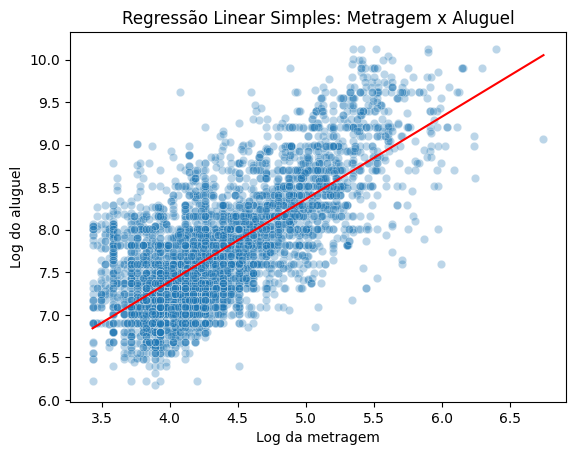

In [11]:
sns.scatterplot(
    x=X_train['log_metragem'],
    y=y_train,
    alpha=0.3
)

sns.lineplot(
    x=X_train['log_metragem'],
    y=modelo_simples.predict(X_train_simples),
    color='red'
)

plt.title('Regressão Linear Simples: Metragem x Aluguel')
plt.xlabel('Log da metragem')
plt.ylabel('Log do aluguel')
plt.show()

Nossa equação seria:  Com o intercepto 3,513 e o coeficiente 0,969, a equação é:

log(aluguel) = 3,513 + 0,969 × log(metragem)

Como as duas variáveis estão em log, o coeficiente tem uma leitura útil: se a metragem aumenta 1%, o aluguel aumenta cerca de 0,97%. Ou seja, o aluguel cresce quase na mesma proporção da metragem: um imóvel com o dobro do tamanho tem, em média, um aluguel quase o dobro. O intercepto (3,513) é o valor do log do aluguel quando o log da metragem é zero, e não tem leitura prática aqui.

c) Calcule o R quadrado para o modelo de treinamento. Não esqueça de avaliar e trazer em formato de insight se esse resultado te parece bom ou não.

In [12]:
from sklearn.metrics import r2_score

# Previsões do modelo nos dados de TREINO
y_pred_train = modelo_simples.predict(X_train_simples)

# R² de treino
r2_treino = r2_score(y_train_simples, y_pred_train)
print(f"R² do modelo de treinamento: {r2_treino:.3f}")
print(f"Ou seja, {r2_treino*100:.1f}% da variação do log do aluguel é explicada pela metragem")

R² do modelo de treinamento: 0.527
Ou seja, 52.7% da variação do log do aluguel é explicada pela metragem


O R² do modelo de regressão linear simples no conjunto de treinamento foi de 0,53, o que indica que a metragem, isoladamente, explica cerca de 53% da variação do valor do aluguel (em escala logarítmica). Considero o resultado moderado e adequado para um modelo com uma única variável: a metragem é claramente um fator importante do aluguel (coeficiente de 0,969, ou seja, um aumento de 1% na metragem está associado a um aumento de cerca de 0,97% no aluguel). No entanto, cerca de 47% da variação permanece sem explicação, provavelmente devido a variáveis ausentes no modelo, como número de vagas, suítes e condomínio, e a fatores que nem estão no dataset, como a localização do imóvel. Isso justifica a próxima etapa de incluir mais variáveis no modelo (regressão linear múltipla), esperando um R² maior.

D) Plote o gráfico da reta de regressão encontrada e traga insights acerca da dispersão dos pontos e ajuste da reta.

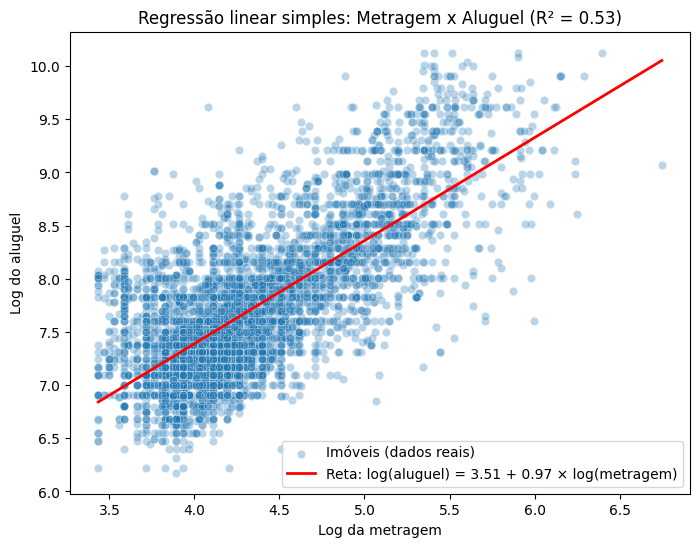

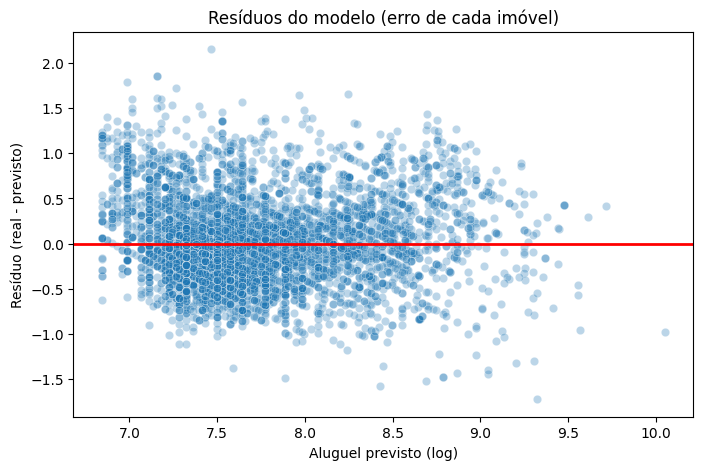

R² treino: 0.527
Erro típico (desvio dos resíduos): 0.468 (em escala log)
Em percentual aproximado: ±60% sobre o aluguel previsto


In [13]:
# %% 1. Números que vamos usar no gráfico
a = modelo_simples.intercept_           # intercepto
b = modelo_simples.coef_[0]             # coeficiente (inclinação)
y_pred = modelo_simples.predict(X_train_simples)
r2 = r2_score(y_train_simples, y_pred)

# %% 2. GRÁFICO 1 - Pontos reais + reta de regressão
# Criamos uma sequência ordenada de valores de x para a reta sair limpa
x_linha = np.linspace(X_train_simples['log_metragem'].min(),
                      X_train_simples['log_metragem'].max(), 100)
y_linha = a + b * x_linha

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_train_simples['log_metragem'], y=y_train_simples,
                alpha=0.3, label='Imóveis (dados reais)')
plt.plot(x_linha, y_linha, color='red', linewidth=2,
         label=f'Reta: log(aluguel) = {a:.2f} + {b:.2f} × log(metragem)')
plt.title(f'Regressão linear simples: Metragem x Aluguel (R² = {r2:.2f})')
plt.xlabel('Log da metragem')
plt.ylabel('Log do aluguel')
plt.legend()
plt.show()

# %% 3. GRÁFICO 2 - Resíduos (erro de cada imóvel) para avaliar o ajuste
# Resíduo = valor real - valor previsto pela reta
residuos = y_train_simples - y_pred

plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_pred, y=residuos, alpha=0.3)
plt.axhline(0, color='red', linewidth=2)
plt.title('Resíduos do modelo (erro de cada imóvel)')
plt.xlabel('Aluguel previsto (log)')
plt.ylabel('Resíduo (real - previsto)')
plt.show()

# %% 4. Números que ajudam a escrever os insights
print(f"R² treino: {r2:.3f}")
print(f"Erro típico (desvio dos resíduos): {residuos.std():.3f} (em escala log)")
print(f"Em percentual aproximado: ±{(np.exp(residuos.std()) - 1) * 100:.0f}% sobre o aluguel previsto")

O gráfico mostra uma relação positiva entre metragem e aluguel: a reta de regressão sobe e acompanha a tendência geral dos dados, consistente com o coeficiente de 0,97 (um aumento de 1% na metragem está associado a um aumento de cerca de 0,97% no aluguel). O R² de treino foi de 0,527, ou seja, a metragem sozinha explica cerca de 52,7% da variação do aluguel, resultado moderado e adequado para um modelo com uma única variável. A dispersão dos pontos em torno da reta é considerável: imóveis com a mesma metragem apresentam aluguéis bastante diferentes, o que indica a influência de outros fatores, como vagas, suítes, condomínio e, principalmente, a localização, que não está no dataset. Os resíduos se distribuem em torno de zero, sem curvatura evidente, indicando que a reta é uma aproximação adequada da relação, mas há mais imóveis muito acima da previsão do que muito abaixo, sugerindo imóveis de alto padrão que o modelo subestima. O desvio dos resíduos foi de 0,468 (escala log), o que equivale a um aluguel real tipicamente entre 37% abaixo e 60% acima do valor previsto. Conclui-se que o modelo captura bem a tendência, mas não é preciso para prever o aluguel de imóveis individuais, o que justifica a inclusão de mais variáveis em um modelo de regressão múltipla.

E) Para finalizar vamos aplicar o modelo a base de teste. Essa etapa é nova, então agora vocês avaliaram como o modelo treinado se saiu com a base de testes.
Para isso altere no código abaixo o nome do seu modelo de regressão:

In [14]:
from sklearn.metrics import r2_score, mean_absolute_error
import numpy as np

# O modelo foi treinado só com log_metragem, então o teste também usa só essa coluna
X_test_simples = X_test[['log_metragem']]
y_pred_test = modelo_simples.predict(X_test_simples)

# R² no teste (em escala log), comparado com o do treino (0,527)
r2_teste = r2_score(y_test, y_pred_test)
print(f"R² treino: 0.527")
print(f"R² teste:  {r2_teste:.3f}")

# Erro médio em reais (desfazendo o log)
mae = mean_absolute_error(np.expm1(y_test), np.expm1(y_pred_test))
print(f"Erro médio absoluto no teste: R$ {mae:,.0f}")

R² treino: 0.527
R² teste:  0.527
Erro médio absoluto no teste: R$ 1,090


O modelo de regressão linear simples, treinado apenas com a metragem, apresentou R² de 0,527 na base de treino e de 0,527 na base de teste. A diferença desprezível entre os dois resultados indica que o modelo generaliza bem para dados novos e não apresenta sinais de sobreajuste, o que é esperado em um modelo simples, com apenas dois parâmetros, avaliado em uma base de teste de 1.431 imóveis. No entanto, o desempenho é moderado: a metragem explica cerca de 53% da variação do aluguel, e o erro médio absoluto no teste foi de R$ 1.090, valor  elevado  quando comparado ao aluguel mediano da base (R$ 2.000). Isso mostra que o modelo capta a tendência de que imóveis maiores têm aluguéis maiores, mas não é preciso para prever o aluguel de um imóvel específico. A limitação decorre da falta de informação (uma única variável), e não de ajuste excessivo. Como próximos passos, recomenda-se incluir variáveis como N_Vagas, N_Suites e condomínio em uma regressão linear múltipla, tomando cuidado com a multicolinearidade entre N_banheiros e N_Suites (r = 0,94), e, se possível, incorporar a localização do imóvel.

In [15]:
# Usando o modelo treinado para fazer previsões sobre os dados de teste
previsoes = modelo_simples.predict(X_test[['log_metragem']])

# Avaliando o desempenho do modelo usando o R²
r2 = modelo_simples.score(X_test[['log_metragem']], y_test)

print("Coeficiente de Determinação (R²) nos Dados de Teste:", r2)


Coeficiente de Determinação (R²) nos Dados de Teste: 0.5273841173515825


Se o valor do coeficiente de determinação (R²) para os dados de treinamento for melhor (ou seja, mais próximo de 1) do que o R² para os dados de teste, isso sugere que o modelo está superajustado aos dados de treinamento. Isso significa que o modelo pode estar se ajustando muito bem aos padrões específicos nos dados de treinamento, mas pode não generalizar bem para novos dados que não foram vistos durante o treinamento.

Por outro lado, se o R² para os dados de teste for melhor do que o R² para os dados de treinamento, isso pode ser indicativo de que o modelo está subajustado. Isso significa que o modelo não está se ajustando adequadamente aos padrões nos dados de treinamento e não está capturando a relação entre as variáveis independentes e dependentes de forma eficaz.

Idealmente, gostaríamos que o valor do R² fosse consistente entre os dados de treinamento e teste, indicando que o modelo é capaz de generalizar bem para novos dados. Se houver uma grande diferença entre os valores de R² para os dados de treinamento e teste, isso sugere que o modelo pode precisar de ajustes para melhorar sua capacidade de generalização.

F) Avalie com suas palavras o valor do r quadrado encontrado no treino e no teste.

O R² nos dados de teste foi de 0,527, praticamente idêntico ao obtido no treino (0,527). Isso indica que o modelo generaliza bem para dados novos e não apresenta sobreajuste. Ainda assim, o desempenho é moderado: a metragem sozinha explica cerca de 53% da variação do aluguel, e os outros 47% dependem de fatores que o modelo não vê, como vagas, suítes, condomínio e localização. Uma regressão linear múltipla seria o próximo passo natural para melhorar o resultado.

# 5 - Aplicação do modelo de regressão linear multipla!

A) Vamos refazer os passos anteriores porém para regressão multipla, com todas variáveis dependentes. Comece separando a base treino e teste, dessa vez com todas variáveis para X.

Aqui é só refazer os passos do exercicio 3 porém ao invés de trazer para X apenas metragem, você deve trazer todas colunas (exceto a valor do aluguel).

In [20]:
from sklearn.model_selection import train_test_split

# Todas as variáveis explicativas (sem o aluguel e sem colunas derivadas dele)
colunas_x = ['log_metragem', 'log_condominio', 'sem_condominio',
             'N_Quartos', 'N_banheiros', 'N_Suites', 'N_Vagas']

X = df_tratado[colunas_x].copy()
X['log_condominio'] = X['log_condominio'].fillna(0)   # imóveis sem condomínio
y = df_tratado['log_aluguel']

# Mesma divisão do exercício 3 (random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('y_train:', y_train.shape, '| y_test:', y_test.shape)
print('Valores vazios em X_train:', X_train.isnull().sum().sum())

X_train: (5723, 7) | X_test: (1431, 7)
y_train: (5723,) | y_test: (1431,)
Valores vazios em X_train: 0


B) Faça o modelo de regressão linear multipla aplicado só a base de treino.

In [22]:
from sklearn.linear_model import LinearRegression

modelo_multiplo = LinearRegression()
modelo_multiplo.fit(X_train, y_train)

print('Intercepto:', modelo_multiplo.intercept_)

coeficientes = pd.DataFrame({
    'Variável': X_train.columns,
    'Coeficiente': modelo_multiplo.coef_
}).sort_values('Coeficiente', key=abs, ascending=False)
display(coeficientes)

equacao = f"log(aluguel) = {modelo_multiplo.intercept_:.3f}"
for nome, coef in zip(X_train.columns, modelo_multiplo.coef_):
    equacao += f" + ({coef:.3f} × {nome})"
print(equacao)

Intercepto: 3.09898252869524


,Variável,Coeficiente
2,sem_condominio,1.792549
0,log_metragem,0.661751
1,log_condominio,0.297548
3,N_Quartos,-0.219510
6,N_Vagas,0.099242
5,N_Suites,0.069103
4,N_banheiros,0.053928


log(aluguel) = 3.099 + (0.662 × log_metragem) + (0.298 × log_condominio) + (1.793 × sem_condominio) + (-0.220 × N_Quartos) + (0.054 × N_banheiros) + (0.069 × N_Suites) + (0.099 × N_Vagas)


O modelo de regressão linear múltipla foi treinado apenas com a base de treino, utilizando as sete variáveis explicativas. A equação obtida foi: log(aluguel) = 3,099 + 0,662×log_metragem + 0,298×log_condominio + 1,793×sem_condominio − 0,220×N_Quartos + 0,054×N_banheiros + 0,069×N_Suites + 0,099×N_Vagas. A metragem e o condomínio têm efeito positivo (elasticidades de 0,66 e 0,30), e cada vaga adicional está associada a um aumento de cerca de 10% no aluguel. O coeficiente da metragem caiu em relação ao modelo simples (0,97), pois agora parte do efeito é atribuída às demais variáveis. O coeficiente negativo de N_Quartos deve ser lido mantendo a metragem constante: um quarto a mais representa o mesmo espaço dividido em mais cômodos. O coeficiente de sem_condominio funciona como um ajuste técnico para os imóveis em que o log do condomínio foi preenchido com zero, e não deve ser interpretado isoladamente. Os efeitos de N_banheiros e N_Suites são pequenos por serem variáveis fortemente correlacionadas (r = 0,94), que dividem entre si a mesma informação.


C) Traga o valor do R quadrado e avalie o valor encontrado.

In [23]:
from sklearn.metrics import r2_score
import numpy as np

# Previsões do modelo múltiplo nos dados de treino
y_pred_treino_m = modelo_multiplo.predict(X_train)

# R² de treino
r2_treino_m = r2_score(y_train, y_pred_treino_m)

# R² ajustado (penaliza variáveis que não ajudam)
n = X_train.shape[0]   # número de imóveis
p = X_train.shape[1]   # número de variáveis
r2_ajustado = 1 - (1 - r2_treino_m) * (n - 1) / (n - p - 1)

# Erro típico em escala log e em percentual
desvio = (y_train - y_pred_treino_m).std()

print(f"R² treino (múltiplo):  {r2_treino_m:.3f}")
print(f"R² ajustado:           {r2_ajustado:.3f}")
print(f"R² treino (simples):   0.527")
print(f"Ganho:                 {r2_treino_m - 0.527:+.3f}")
print(f"Desvio dos resíduos:   {desvio:.3f}  (simples: 0.468)")
print(f"Erro típico: {np.exp(-desvio)-1:.0%} a +{np.exp(desvio)-1:.0%} sobre o previsto")

R² treino (múltiplo):  0.646
R² ajustado:           0.646
R² treino (simples):   0.527
Ganho:                 +0.119
Desvio dos resíduos:   0.405  (simples: 0.468)
Erro típico: -33% a +50% sobre o previsto


O modelo de regressão linear múltipla apresentou R² de 0,646 na base de treino, o que significa que explica cerca de 64,6% da variação do aluguel, contra 0,527 do modelo simples, um ganho de 0,119 pontos. O R² ajustado foi igual ao R² comum (0,646), indicando que o ganho não decorre apenas do aumento no número de variáveis. O desvio dos resíduos caiu de 0,468 para 0,405 em escala log, e o erro típico passou de -37% a +60% para -33% a +50% sobre o valor previsto, uma melhora real, ainda que moderada. Considero o resultado moderado, próximo de bom: a inclusão das demais variáveis melhorou claramente o ajuste, mas o erro continua elevado para a previsão de imóveis individuais. Os cerca de 35% da variação não explicada provavelmente se devem a fatores ausentes no dataset, principalmente a localização, além do padrão de acabamento e da idade do imóvel. Esse resultado ainda precisa ser confirmado na base de teste, para verificar se o modelo generaliza bem para dados novos.


D) Para finalizar aplique o modelo a base de teste e traga o r quadrado de teste.
Dica: Você pode usar os códigos do exercício anterior.

In [24]:
from sklearn.metrics import r2_score, mean_absolute_error
import numpy as np

# Previsões do modelo múltiplo na base de TESTE
y_pred_teste_m = modelo_multiplo.predict(X_test)

# R² de teste e comparação com o treino
r2_teste_m = r2_score(y_test, y_pred_teste_m)
print(f"R² treino (múltiplo): {r2_treino_m:.3f}")
print(f"R² teste  (múltiplo): {r2_teste_m:.3f}")
print(f"Diferença treino - teste: {r2_treino_m - r2_teste_m:+.3f}")

# Erro médio em reais (desfazendo o log) e comparação com o modelo simples
mae_m = mean_absolute_error(np.expm1(y_test), np.expm1(y_pred_teste_m))
print(f"MAE teste (múltiplo): R$ {mae_m:,.0f}   (simples: R$ 1.090)")

R² treino (múltiplo): 0.646
R² teste  (múltiplo): 0.640
Diferença treino - teste: +0.006
MAE teste (múltiplo): R$ 996   (simples: R$ 1.090)


O modelo de regressão linear múltipla apresentou R² de 0,640 na base de teste, contra 0,646 no treino, uma diferença de apenas 0,006. Como os resultados são muito próximos, conclui-se que o modelo generaliza bem para dados novos e não apresenta sinais de sobreajuste. Em comparação com o modelo simples (R² de teste de 0,527), o modelo múltiplo explica 64% da variação do aluguel, um ganho de 0,113 pontos, e o erro médio absoluto no teste caiu de R$ 1.090 para R$ 996, uma redução de cerca de 8,6%. A melhora em reais é menor do que a observada no R², possivelmente porque o erro em reais é dominado pelos imóveis de maior valor, nos quais o modelo ainda erra bastante. Ainda assim, o erro permanece relevante frente ao aluguel mediano de R$ 2.000 (cerca de 50%), e aproximadamente 36% da variação continua sem explicação, provavelmente por fatores ausentes no dataset, como a localização do imóvel.

E) Compare os r quadrados encontrados pela regressão linear e pela regressão múltipla. Qual modelo te parece melhor? Por qual motivo acredita que isso ocorreu?

O modelo de regressão linear múltipla apresentou desempenho superior ao da regressão linear simples. O R² passou de 0,527 para 0,646 no treino e de 0,527 para 0,640 no teste, e o erro médio absoluto no teste caiu de R$ 1.090 para R$ 996. Como o ganho se manteve na base de teste e a diferença entre treino e teste foi de apenas 0,006, conclui-se que a melhora é real e que o modelo generaliza bem, sem sinais de sobreajuste. Isso ocorreu porque o aluguel é influenciado por diversos fatores além da metragem: o modelo simples considera apenas o tamanho do imóvel, enquanto o múltiplo incorpora também o valor do condomínio, o número de vagas, suítes, banheiros e quartos, que funcionam como indicadores do padrão do imóvel. A queda do coeficiente da metragem (de 0,97 para 0,66) sugere que, no modelo simples, ela absorvia parte do efeito dessas outras variáveis. Apesar da melhora, o ganho foi moderado e cerca de 36% da variação continua sem explicação, provavelmente por fatores ausentes no dataset, como a localização do imóvel. Portanto, o modelo múltiplo é o mais adequado, mas ainda limitado por falta de informação.

